# DataHub — Galaxy Star Formation Rate Prediction
## Midterm + Final Scientific Report Template

This notebook is both your **analysis code** and your **scientific report**. Use the **same notebook for both submission stages**.

- **Part I — Midterm Report:** complete all required Part I sections and submit the notebook.
- **Part II — Final Report:** continue in the same notebook, preserve Part I, and complete the final analysis, code, results, and discussion.

## Participant Information

**Application ID**

**email:**

---
# Part I — Midterm Report

**Goal:** establish a scientifically motivated modeling plan. Part I should demonstrate that you understand the prediction problem, have inspected the data carefully, established a defensible validation procedure, and produced preliminary results.

### Part I deliverables
1. Problem & objective
2. Data loading and quality checks
3. Exploratory data analysis
4. Data preparation and feature engineering
5. Validation and evaluation strategy
6. Baseline results
7. Preliminary model / proposed method
8. Midterm summary and next-step plan

## 1. Problem & Objective — **STUDENT RESPONSE**

In approximately **150–250 words**, explain:
- what quantity you are predicting;
- what information is available as input;
- why this is a non-trivial regression problem;
- one or more astrophysical considerations that may affect the prediction.

**Response:**  
...

## 2. Setup, Reproducibility & Data Loading

The fixed cells below establish common imports, a random seed, and basic schema checks. You may change the data path if necessary, but do not silently alter the raw data.

In [1]:
# DO NOT MODIFY — core imports and seed
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
pd.set_option("display.max_columns", 100)
print("Random seed:", RANDOM_SEED)

Random seed: 42


In [2]:
# You may change DATA_PATH only if needed.
CANDIDATES = [
    Path("../../Galaxy Features with Position and Velocity for Star Formation Rate Prediction.csv"),  # work/팀원/ 에서 실행할 때
    Path("Galaxy Features with Position and Velocity for Star Formation Rate Prediction.csv"),
    Path("/mnt/data/Galaxy Features with Position and Velocity for Star Formation Rate Prediction.csv"),
]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found. Place the course CSV beside this notebook or update DATA_PATH.")

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Shape: (208437, 15)


,subhalo_id,log10_halo_mass,log10_stellar_mass,log10_BH_mass,log10_main_prog_mass,log10_main_prog_stellar_mass,log10_mass_ratio,log10_overdensity_plus_1,pos_x,pos_y,pos_z,vel_x,vel_y,vel_z,sfr_linear
0,0.0,14.807566,12.812004,10.443699,14.631294,12.589542,-3.239739,2.383863,21.290455,101.703239,118.123352,-287.557892,-62.394615,-30.580877,107.896912
1,1.0,13.870680,12.091579,8.625058,13.819390,11.916792,-6.000000,2.025288,20.735514,101.805397,120.937294,786.127563,258.246796,-680.667908,68.733315
2,2.0,13.672584,12.032370,9.829654,13.620131,11.864630,-6.000000,1.704644,18.711687,103.225121,120.417160,890.943054,-756.617004,-358.727631,0.232002
3,3.0,13.650022,12.019966,9.312719,13.577394,11.849984,-6.000000,1.833376,23.493862,102.198166,113.814438,-92.127396,532.597473,544.153687,12.698732
4,4.0,13.131606,11.563723,9.452775,13.026983,11.395634,-6.000000,1.830341,24.067015,101.780312,112.495789,-187.708572,-224.876968,978.109558,0.715540


In [3]:
# DO NOT MODIFY — schema checks
TARGET = "sfr_linear"
ID_COLUMN = "subhalo_id"
EXPECTED_COLUMNS = [
    "subhalo_id", "log10_halo_mass", "log10_stellar_mass", "log10_BH_mass",
    "log10_main_prog_mass", "log10_main_prog_stellar_mass", "log10_mass_ratio",
    "log10_overdensity_plus_1", "pos_x", "pos_y", "pos_z",
    "vel_x", "vel_y", "vel_z", "sfr_linear"
]
missing = sorted(set(EXPECTED_COLUMNS) - set(df.columns))
if missing:
    raise ValueError(f"Missing expected columns: {missing}")
n_missing_target = int(df[TARGET].isna().sum())
print(f"Missing target values: {n_missing_target}")
if n_missing_target > 0:
    print(f"Dropping {n_missing_target} row(s) with missing target before modeling.")
    df = df.dropna(subset=[TARGET]).copy()
print(f"Schema check passed. Samples available for modeling: {len(df):,}")


Missing target values: 0
Schema check passed. Samples available for modeling: 208,437


### 2.1 Data Quality Notes — **STUDENT RESPONSE**

Report the dataset size, missing values, duplicate handling (if any), and any other data-quality issue you found. Remember that **`sfr_linear = 0` is a valid physical target and is not the same as a missing value**.

**Response:**  
...

In [4]:
# 2.1 데이터 품질 점검 (james) — 값은 세기만 하고 지우거나 바꾸지 않는다.
FEATURES = [c for c in df.columns if c not in [ID_COLUMN, TARGET]]  # 4절 FINAL_FEATURES와 같은 규칙

# 1. 크기와 변수 이름
print("행 × 열:", df.shape)
print("변수 이름:", list(df.columns))
print("입력 피처 수:", len(FEATURES))

# 2. 열별 타입과 결측치
col_info = pd.DataFrame({"dtype": df.dtypes.astype(str), "NaN": df.isna().sum()})
display(col_info)
print("NaN 총개수:", int(df.isna().sum().sum()))

# 3. 중복
print("전체 열 중복 행:", int(df.duplicated().sum()))
print("subhalo_id 중복:", int(df[ID_COLUMN].duplicated().sum()))
print("subhalo_id가 정수인가:", bool((df[ID_COLUMN] % 1 == 0).all()),
      "| 범위:", int(df[ID_COLUMN].min()), "~", int(df[ID_COLUMN].max()))


행 × 열: (208437, 15)
변수 이름: ['subhalo_id', 'log10_halo_mass', 'log10_stellar_mass', 'log10_BH_mass', 'log10_main_prog_mass', 'log10_main_prog_stellar_mass', 'log10_mass_ratio', 'log10_overdensity_plus_1', 'pos_x', 'pos_y', 'pos_z', 'vel_x', 'vel_y', 'vel_z', 'sfr_linear']
입력 피처 수: 13


,dtype,NaN
subhalo_id,float64,0
log10_halo_mass,float64,0
log10_stellar_mass,float64,0
log10_BH_mass,float64,0
log10_main_prog_mass,float64,0
log10_main_prog_stellar_mass,float64,0
log10_mass_ratio,float64,0
log10_overdensity_plus_1,float64,0
pos_x,float64,0
pos_y,float64,0


NaN 총개수: 0


전체 열 중복 행: 0
subhalo_id 중복: 0
subhalo_id가 정수인가: True | 범위: 0 ~ 976589


In [5]:
# 4. 타깃 sfr_linear
y_all = df[TARGET]
sfr_summary = y_all.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99, 0.999]).round(3)
display(sfr_summary.to_frame("sfr_linear"))
print(f"정확히 0: {int((y_all == 0).sum()):,}개 ({(y_all == 0).mean():.2%})")
print(f"음수: {int((y_all < 0).sum())}개")
print(f"0 < SFR < 0.01: {int(((y_all > 0) & (y_all < 0.01)).sum()):,}개")
print(f"SFR > 100: {int((y_all > 100).sum()):,}개")
print(f"평균 / 중앙값 = {y_all.mean() / y_all.median():.2f}")


,sfr_linear
count,208437.000
mean,3.710
std,11.795
min,0.000
10%,0.343
25%,0.916
50%,1.632
75%,3.286
90%,7.554
99%,34.859


정확히 0: 18,048개 (8.66%)
음수: 0개
0 < SFR < 0.01: 2개
SFR > 100: 270개
평균 / 중앙값 = 2.27


In [6]:
# 5. 특수 값(센티널 후보) 분포 — 같은 값이 많이 반복되는지부터 본다
for col in ["log10_BH_mass", "log10_main_prog_mass", "log10_main_prog_stellar_mass", "log10_mass_ratio"]:
    vc = df[col].round(4).value_counts().head(5)
    print(f"\n[{col}] 가장 많이 나오는 값 (소수 4자리로 반올림)")
    print((vc.to_frame("count").assign(share=(vc / len(df)).round(4))))

bh = df["log10_BH_mass"]
mp = df["log10_main_prog_mass"]
mps = df["log10_main_prog_stellar_mass"]
mr = df["log10_mass_ratio"]
special = pd.DataFrame([
    ("log10_BH_mass == 5.0 (정확히)", (bh == 5.0).sum()),
    ("log10_BH_mass <= 5.01", (bh <= 5.01).sum()),
    ("log10_BH_mass < 5.5", (bh < 5.5).sum()),
    ("log10_main_prog_mass == 6.0", (mp == 6.0).sum()),
    ("log10_main_prog_stellar_mass == 6.0", (mps == 6.0).sum()),
    ("둘 다 6.0 (같은 행)", ((mp == 6.0) & (mps == 6.0)).sum()),
    ("log10_mass_ratio == -6", (mr == -6).sum()),
    ("log10_mass_ratio > -6", (mr > -6).sum()),
], columns=["조건", "개수"])
special["비율"] = (special["개수"] / len(df)).map("{:.2%}".format)
display(special)
print("BH > 5.01인 행의 최솟값:", round(bh[bh > 5.01].min(), 4))
print("mass_ratio > -6인 행의 최솟값:", round(mr[mr > -6].min(), 4), "| 최댓값:", mr.max())
print("main_prog_mass > 6인 행의 최솟값:", round(mp[mp > 6].min(), 4))



[log10_BH_mass] 가장 많이 나오는 값 (소수 4자리로 반올림)
               count   share
log10_BH_mass               
5.0001         31078  0.1491
5.0000         27600  0.1324
5.0002         14495  0.0695
5.0003          8324  0.0399
5.3011          7108  0.0341

[log10_main_prog_mass] 가장 많이 나오는 값 (소수 4자리로 반올림)
                      count   share
log10_main_prog_mass               
6.0000                  762  0.0037
11.1724                  38  0.0002
11.1925                  37  0.0002
11.1251                  36  0.0002
11.0774                  35  0.0002

[log10_main_prog_stellar_mass] 가장 많이 나오는 값 (소수 4자리로 반올림)
                              count   share
log10_main_prog_stellar_mass               
6.0000                          772  0.0037
9.2446                           36  0.0002
9.4331                           34  0.0002
9.5617                           34  0.0002
9.4322                           34  0.0002

[log10_mass_ratio] 가장 많이 나오는 값 (소수 4자리로 반올림)
                   count   share
log10_m

,조건,개수,비율
0,log10_BH_mass == 5.0 (정확히),0,0.00%
1,log10_BH_mass <= 5.01,121546,58.31%
2,log10_BH_mass < 5.5,181335,87.00%
3,log10_main_prog_mass == 6.0,762,0.37%
4,log10_main_prog_stellar_mass == 6.0,772,0.37%
5,둘 다 6.0 (같은 행),762,0.37%
6,log10_mass_ratio == -6,175778,84.33%
7,log10_mass_ratio > -6,32659,15.67%


BH > 5.01인 행의 최솟값: 5.01
mass_ratio > -6인 행의 최솟값: -3.7883 | 최댓값: -0.000282686697
main_prog_mass > 6인 행의 최솟값: 9.3357


In [7]:
# 5-1. 주의 값 추가 확인 (위 표에서 눈에 띈 것)
print("BH 질량, 정확한 값 기준 최빈값 3개:", bh.value_counts().head(3).to_dict())
print(f"BH 5.30~5.31 구간(두 번째 봉우리): {int(bh.between(5.30, 5.31).sum()):,}개 ({bh.between(5.30, 5.31).mean():.1%})")
only_stellar6 = (mps == 6.0) & (mp != 6.0)
print(f"전구체 항성 질량만 6.0 (헤일로 질량은 정상): {int(only_stellar6.sum())}개")
display(df.loc[only_stellar6, ["log10_main_prog_mass", "log10_main_prog_stellar_mass", "log10_stellar_mass", TARGET]].round(3))
halo_lt_star = df["log10_halo_mass"] < df["log10_stellar_mass"]
print(f"헤일로 질량 < 항성 질량인 행: {int(halo_lt_star.sum())}개 ({halo_lt_star.mean():.2%})")


BH 질량, 정확한 값 기준 최빈값 3개: {5.00000048: 13999, 5.00004768: 234, 5.00006866: 233}
BH 5.30~5.31 구간(두 번째 봉우리): 32,597개 (15.6%)
전구체 항성 질량만 6.0 (헤일로 질량은 정상): 10개


,log10_main_prog_mass,log10_main_prog_stellar_mass,log10_stellar_mass,sfr_linear
30736,10.069,6.0,11.358,3.510
43026,9.907,6.0,11.235,2.511
49465,10.055,6.0,11.435,11.262
49841,9.886,6.0,11.280,14.941
53297,9.798,6.0,11.045,11.161
55136,9.995,6.0,11.019,1.849
56888,9.926,6.0,11.186,7.168
62118,9.944,6.0,11.077,5.099
66016,9.744,6.0,10.862,5.257
71206,9.906,6.0,10.602,2.337


헤일로 질량 < 항성 질량인 행: 517개 (0.25%)


In [8]:
# 7. 비유한 값(+inf, -inf) — NaN과 따로 센다
num = df.select_dtypes("number")
nonfinite = pd.DataFrame({
    "+inf": np.isposinf(num).sum(),
    "-inf": np.isneginf(num).sum(),
    "NaN": num.isna().sum(),
})
print("숫자형 열:", num.shape[1], "/", df.shape[1])
print("비유한 값이 있는 열:", list(nonfinite.index[nonfinite.sum(axis=1) > 0]) or "없음")
print("+inf 총개수:", int(nonfinite["+inf"].sum()), "| -inf 총개수:", int(nonfinite["-inf"].sum()))


숫자형 열: 15 / 15
비유한 값이 있는 열: 없음
+inf 총개수: 0 | -inf 총개수: 0


In [9]:
# 8. 상수 열 — 15개 열 전체에서 값이 한 종류뿐인 열, 그리고 한 값이 대부분을 차지하는 열
const_check = pd.DataFrame({
    "고유값 수": df.nunique(),
    "최빈값": df.mode().iloc[0],
    "최빈값 비율": (df.apply(lambda s: s.value_counts(normalize=True).iloc[0])).round(4),
}).sort_values("최빈값 비율", ascending=False)
display(const_check)
print("상수 열(고유값 1개):", list(const_check.index[const_check["고유값 수"] == 1]) or "없음")


,고유값 수,최빈값,최빈값 비율
log10_mass_ratio,32659,-6.000000,0.8433
sfr_linear,189864,0.000000,0.0866
log10_BH_mass,72276,5.000000,0.0672
log10_main_prog_stellar_mass,207098,6.000000,0.0037
log10_main_prog_mass,206349,6.000000,0.0037
log10_overdensity_plus_1,95330,0.040029,0.0001
log10_stellar_mass,195185,9.305265,0.0000
log10_halo_mass,189212,8.000000,0.0000
subhalo_id,208437,0.000000,0.0000
pos_y,207324,78.444397,0.0000


상수 열(고유값 1개): 없음


In [10]:
# 9. 점검 대상 구분 — 위 1~8은 모두 "전체 CSV"(df) 기준이다.
#    공통 분할은 5절(DO NOT MODIFY)에서 만들어진다. 여기서는 같은 인자로 분할을 재현해
#    학습용(train)만의 타깃 통계를 참고로 비교한다. 5절 칸은 고치지 않는다.
_y = df[TARGET]
_regime = (_y > 0).astype(int)
_tr_idx, _va_idx = train_test_split(
    df.index, test_size=0.20, random_state=RANDOM_SEED, stratify=_regime
)
print("전체:", len(df), "| 학습:", len(_tr_idx), "| 검증:", len(_va_idx))

def _target_summary(s):
    return pd.Series({
        "n": len(s), "평균": s.mean(), "중앙값": s.median(),
        "90%": s.quantile(0.90), "99%": s.quantile(0.99), "99.9%": s.quantile(0.999),
        "최댓값": s.max(), "0 비율(%)": (s == 0).mean() * 100, "SFR>100 개수": (s > 100).sum(),
    })
display(pd.DataFrame({
    "전체 CSV": _target_summary(_y),
    "학습(train)": _target_summary(_y.loc[_tr_idx]),
    "검증(val)": _target_summary(_y.loc[_va_idx]),
}).round(3))


전체: 208437 | 학습: 166749 | 검증: 41688


,전체 CSV,학습(train),검증(val)
n,208437.000,166749.000,41688.000
평균,3.710,3.700,3.751
중앙값,1.632,1.633,1.627
90%,7.554,7.551,7.579
99%,34.859,35.011,34.078
99.9%,112.781,110.600,125.227
최댓값,2145.373,2145.373,884.107
0 비율(%),8.659,8.659,8.660
SFR>100 개수,270.000,209.000,61.000


In [11]:
# 10. 전구체 헤일로 질량은 정상(≠ 6.0)인데 전구체 항성 질량만 6.0인 10개 은하
g10 = (df["log10_main_prog_stellar_mass"] == 6.0) & (df["log10_main_prog_mass"] != 6.0)
print("해당 은하 수:", int(g10.sum()), "| 학습:", int(g10.loc[_tr_idx].sum()), "| 검증:", int(g10.loc[_va_idx].sum()))
display(df.loc[g10].round(3))

# 비교 기준: 나머지 전체, 그리고 현재 항성 질량이 비슷한(같은 범위) 나머지 은하
lo, hi = df.loc[g10, "log10_stellar_mass"].min(), df.loc[g10, "log10_stellar_mass"].max()
similar = (~g10) & df["log10_stellar_mass"].between(lo, hi)
cols = ["log10_halo_mass", "log10_stellar_mass", "log10_BH_mass", "log10_main_prog_mass",
        "log10_mass_ratio", "log10_overdensity_plus_1", TARGET]
cmp10 = pd.DataFrame({
    "10개 (중앙값)": df.loc[g10, cols].median(),
    f"항성 질량 {lo:.2f}~{hi:.2f}인 나머지 (중앙값)": df.loc[similar, cols].median(),
    "나머지 전체 (중앙값)": df.loc[~g10, cols].median(),
}).round(3)
cmp10.loc["SFR = 0 비율(%)"] = [(df.loc[m, TARGET] == 0).mean() * 100 for m in (g10, similar, ~g10)]
cmp10.loc["최근 병합 비율(%) (mass_ratio > -6)"] = [(df.loc[m, "log10_mass_ratio"] > -6).mean() * 100 for m in (g10, similar, ~g10)]
cmp10.loc["n"] = [g10.sum(), similar.sum(), (~g10).sum()]
display(cmp10.round(3))


해당 은하 수: 10 | 학습: 8 | 검증: 2


,subhalo_id,log10_halo_mass,log10_stellar_mass,log10_BH_mass,log10_main_prog_mass,log10_main_prog_stellar_mass,log10_mass_ratio,log10_overdensity_plus_1,pos_x,pos_y,pos_z,vel_x,vel_y,vel_z,sfr_linear
30736,129846.0,13.325,11.358,5.301,10.069,6.0,-0.144,1.269,28.858,198.584,11.311,383.411,373.581,40.684,3.510
43026,178550.0,13.137,11.235,5.604,9.907,6.0,-6.000,1.027,19.950,96.055,150.028,274.661,362.304,-156.417,2.511
49465,203353.0,12.938,11.435,5.000,10.055,6.0,-0.168,0.865,22.788,47.631,5.149,7.284,-442.530,-238.463,11.262
49841,204808.0,12.959,11.280,5.303,9.886,6.0,-0.012,0.878,75.187,42.358,7.008,-546.956,-70.521,-249.324,14.941
53297,217928.0,12.871,11.045,5.301,9.798,6.0,-6.000,0.862,106.025,153.248,164.700,240.663,153.171,46.054,11.161
55136,224909.0,12.828,11.019,5.302,9.995,6.0,-0.143,0.811,6.539,153.061,17.836,-125.066,72.456,-161.129,1.849
56888,231313.0,12.791,11.186,5.303,9.926,6.0,-0.076,0.684,57.659,130.080,159.867,0.846,112.788,95.000,7.168
62118,250269.0,12.659,11.077,5.000,9.944,6.0,-6.000,0.735,65.292,87.665,5.250,-420.196,222.809,-239.303,5.099
66016,264051.0,12.538,10.862,5.000,9.744,6.0,-6.000,1.526,3.858,178.105,4.105,-179.463,-212.145,205.211,5.257
71206,281327.0,12.480,10.602,5.000,9.906,6.0,-6.000,0.632,78.968,79.504,183.376,62.601,37.856,118.942,2.337


,10개 (중앙값),항성 질량 10.60~11.43인 나머지 (중앙값),나머지 전체 (중앙값)
log10_halo_mass,12.850,12.252,11.383
log10_stellar_mass,11.131,10.873,9.838
log10_BH_mass,5.301,5.624,5.001
log10_main_prog_mass,9.917,12.120,11.244
log10_mass_ratio,-3.084,-6.000,-6.000
log10_overdensity_plus_1,0.863,0.837,0.665
sfr_linear,5.178,9.694,1.632
SFR = 0 비율(%),0.000,11.129,8.659
최근 병합 비율(%) (mass_ratio > -6),50.000,40.623,15.667
n,10.000,24666.000,208427.000


In [12]:
# 11. 헤일로 질량 < 항성 질량인 517개 은하 vs 나머지
g517 = df["log10_halo_mass"] < df["log10_stellar_mass"]
print("해당 은하 수:", int(g517.sum()), "| 학습:", int(g517.loc[_tr_idx].sum()), "| 검증:", int(g517.loc[_va_idx].sum()))

def _q(s):
    return s.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).rename(lambda p: f"{int(p*100)}%")

tbl = pd.DataFrame({
    ("SFR = 0 비율(%)", "517개"): [(df.loc[g517, TARGET] == 0).mean() * 100],
    ("SFR = 0 비율(%)", "나머지"): [(df.loc[~g517, TARGET] == 0).mean() * 100],
    ("SFR = 0 비율(%) — 학습만", "517개"): [(df.loc[_tr_idx][g517.loc[_tr_idx]][TARGET] == 0).mean() * 100],
    ("SFR = 0 비율(%) — 학습만", "나머지"): [(df.loc[_tr_idx][~g517.loc[_tr_idx]][TARGET] == 0).mean() * 100],
}).T.round(2)
tbl.columns = ["값"]
display(tbl)

for col, name in [("log10_overdensity_plus_1", "주변 밀도"), ("log10_stellar_mass", "항성 질량"), ("log10_halo_mass", "헤일로 질량")]:
    print(f"\n[{name}: {col}] 분위수")
    display(pd.DataFrame({"517개": _q(df.loc[g517, col]), "나머지": _q(df.loc[~g517, col])}).round(3))

print("\n(halo − stellar) 차이 분포 (517개):")
display(_q(df.loc[g517, "log10_halo_mass"] - df.loc[g517, "log10_stellar_mass"]).round(3).to_frame("dex"))


해당 은하 수: 517 | 학습: 415 | 검증: 102


값
SFR = 0 비율(%)       517개  42.94
                    나머지    8.57
SFR = 0 비율(%) — 학습만 517개  41.69
                    나머지    8.58


[주변 밀도: log10_overdensity_plus_1] 분위수


,517개,나머지
10%,0.777,0.058
25%,1.003,0.303
50%,1.351,0.663
75%,1.697,1.139
90%,2.078,1.608



[항성 질량: log10_stellar_mass] 분위수


,517개,나머지
10%,9.690,9.396
25%,10.690,9.547
50%,11.012,9.837
75%,11.234,10.270
90%,11.447,10.742



[헤일로 질량: log10_halo_mass] 분위수


,517개,나머지
10%,9.434,10.693
25%,10.499,11.082
50%,10.784,11.384
75%,11.009,11.721
90%,11.254,12.143



(halo − stellar) 차이 분포 (517개):


,dex
10%,-0.425
25%,-0.312
50%,-0.187
75%,-0.086
90%,-0.028


In [13]:
# 6. 입력 피처 13개의 범위
feat_range = df[FEATURES].agg(["min", "median", "max"]).T.round(3)
feat_range["고유값 수"] = df[FEATURES].nunique()
display(feat_range)


,min,median,max,고유값 수
log10_halo_mass,8.000,11.383,14.827,189212
log10_stellar_mass,9.300,9.838,12.962,195185
log10_BH_mass,5.000,5.001,11.162,72276
log10_main_prog_mass,6.000,11.244,14.702,206349
log10_main_prog_stellar_mass,6.000,9.626,12.746,207098
log10_mass_ratio,-6.000,-6.000,-0.000,32659
log10_overdensity_plus_1,-0.581,0.665,2.512,95330
pos_x,0.000,91.635,200.000,207401
pos_y,0.000,106.818,199.999,207324
pos_z,0.002,101.473,200.000,207401


## 3. Exploratory Data Analysis (EDA) — **STUDENT WORK**

Your EDA should be selective and scientifically useful rather than a gallery of plots. Include **at least two analyses/figures that influence a later modeling decision**. At minimum, examine the target distribution and relevant relationships between predictors and SFR.

For every important figure/table, add a short interpretation directly below it: **What does it show? Why might the pattern occur? How does it affect your modeling choices?**

In [14]:
# STUDENT TODO — starter summary
print(df[TARGET].describe(percentiles=[0.5, 0.9, 0.99]))
zero_fraction = (df[TARGET] == 0).mean()
print(f"Exact zero-SFR fraction: {zero_fraction:.2%}")

# Add your EDA here.

count    208437.000000
mean          3.709985
std          11.794583
min           0.000000
50%           1.631928
90%           7.554342
99%          34.859419
max        2145.372800
Name: sfr_linear, dtype: float64
Exact zero-SFR fraction: 8.66%


In [15]:
# EDA 1. 주변 밀도가 높을수록 SFR = 0 비율이 커지는가? — 학습 데이터(166,749개)만 사용
#    분할은 위 9번 칸에서 5절(DO NOT MODIFY)과 같은 인자로 재현한 _tr_idx를 쓴다.
train = df.loc[_tr_idx]
assert len(train) == 166749

DENS = "log10_overdensity_plus_1"
edges = np.arange(-0.75, 2.75 + 1e-9, 0.25)          # 0.25 dex 폭 구간 14개
dens_bin = pd.cut(train[DENS], bins=edges)
assert dens_bin.notna().all()                          # 모든 은하가 어떤 구간에 들어감

def wilson(k, n, z=1.96):
    """비율의 95% Wilson 신뢰구간 (개수가 적은 구간에서도 0~1 안에 머문다)"""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

g = train.groupby(dens_bin, observed=True)[TARGET]
zero_by_dens = pd.DataFrame({"은하 수": g.size(), "SFR=0 수": g.apply(lambda s: int((s == 0).sum()))})
zero_by_dens["SFR=0 비율(%)"] = zero_by_dens["SFR=0 수"] / zero_by_dens["은하 수"] * 100
lo_ci, hi_ci = wilson(zero_by_dens["SFR=0 수"], zero_by_dens["은하 수"])
zero_by_dens["95% CI 하한(%)"] = lo_ci * 100
zero_by_dens["95% CI 상한(%)"] = hi_ci * 100
zero_by_dens["전체 0 중 비중(%)"] = zero_by_dens["SFR=0 수"] / zero_by_dens["SFR=0 수"].sum() * 100
zero_by_dens["밀도 배수(구간 오른쪽 끝, 10^x)"] = [round(10 ** iv.right, 2) for iv in zero_by_dens.index]
display(zero_by_dens.round(2))
print(f"학습 데이터 전체 SFR=0 비율: {(train[TARGET] == 0).mean():.2%}  ({int((train[TARGET] == 0).sum()):,} / {len(train):,})")


,은하 수,SFR=0 수,SFR=0 비율(%),95% CI 하한(%),95% CI 상한(%),전체 0 중 비중(%),"밀도 배수(구간 오른쪽 끝, 10^x)"
log10_overdensity_plus_1,,,,,,,
"(-0.75, -0.5]",14,0,0.00,0.00,21.53,0.00,0.32
"(-0.5, -0.25]",1412,0,0.00,0.00,0.27,0.00,0.56
"(-0.25, 0.0]",10622,0,0.00,0.00,0.04,0.00,1.00
"(0.0, 0.25]",23451,2,0.01,0.00,0.03,0.01,1.78
"(0.25, 0.5]",29501,7,0.02,0.01,0.05,0.05,3.16
"(0.5, 0.75]",27202,21,0.08,0.05,0.12,0.15,5.62
"(0.75, 1.0]",22243,50,0.22,0.17,0.30,0.35,10.00
"(1.0, 1.25]",17559,162,0.92,0.79,1.08,1.12,17.78
"(1.25, 1.5]",13834,591,4.27,3.95,4.62,4.09,31.62


학습 데이터 전체 SFR=0 비율: 8.66%  (14,438 / 166,749)


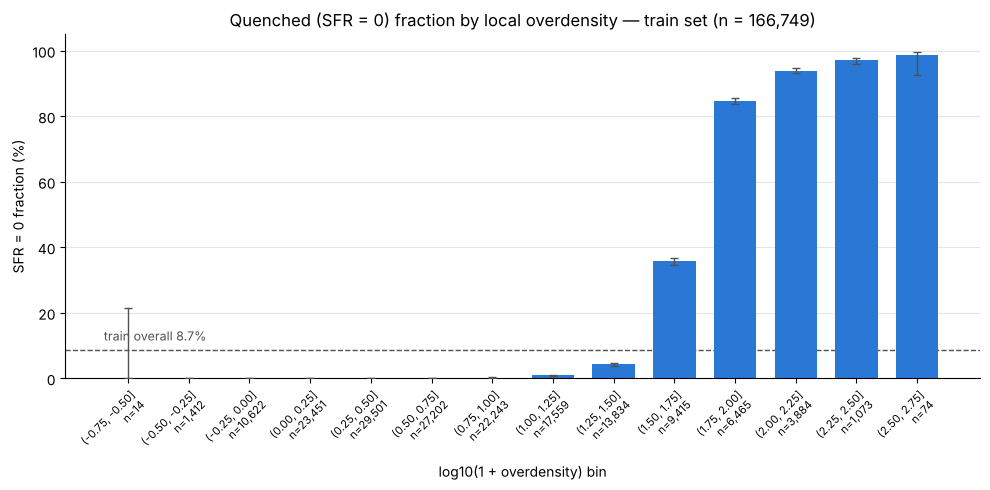

In [16]:
# 그림: 밀도 구간별 SFR = 0 비율 (막대 = 비율, 세로선 = 95% Wilson 구간)
#    글꼴 문제를 피하려고 그림 안 글자는 영어로 쓴다.
x = np.arange(len(zero_by_dens))
rate = zero_by_dens["SFR=0 비율(%)"].to_numpy()
yerr = np.vstack([rate - zero_by_dens["95% CI 하한(%)"], zero_by_dens["95% CI 상한(%)"] - rate])
labels = [f"({iv.left:.2f}, {iv.right:.2f}]" for iv in zero_by_dens.index]
overall = (train[TARGET] == 0).mean() * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x, rate, width=0.7, color="#2a78d6", zorder=2)
ax.errorbar(x, rate, yerr=yerr, fmt="none", ecolor="#52514e", elinewidth=1, capsize=3, zorder=3)
ax.axhline(overall, color="#52514e", lw=1, ls="--", zorder=1)
ax.text(-0.4, overall + 2, f"train overall {overall:.1f}%", ha="left", va="bottom", fontsize=9, color="#52514e")
tick_labels = [f"{lab}\nn={n:,}" for lab, n in zip(labels, zero_by_dens["은하 수"])]
ax.set_xticks(x, tick_labels, rotation=45, ha="right", rotation_mode="anchor", fontsize=8)
ax.set_ylim(0, 105)
ax.set_yticks(range(0, 101, 20))
ax.set_ylabel("SFR = 0 fraction (%)")
ax.set_xlabel("log10(1 + overdensity) bin")
ax.set_title("Quenched (SFR = 0) fraction by local overdensity — train set (n = 166,749)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e5e0", lw=0.8, zorder=0)
plt.tight_layout()
plt.show()


#### EDA 1 코멘트 — 주변 밀도와 SFR = 0의 관계 (학습 데이터 166,749개)

**Finding**
- `log10_overdensity_plus_1`을 0.25 dex 간격으로 나눠 보면, 밀도가 높아질수록 SFR = 0 비율이 **모든 구간에서 단조 증가**한다.
- 증가는 일정하지 않고 급격하다. (1.00, 1.25] **0.92%** → (1.25, 1.50] **4.27%** → (1.50, 1.75] **35.70%** → (1.75, 2.00] **84.76%** → (2.00, 2.25] **93.95%**. 학습 데이터 전체의 SFR = 0 비율은 **8.66%**이다.
- SFR = 0 은하의 **94.2%가 밀도 ≥ 1.5**인 영역에 있다. 그러나 밀도 ≥ 1.5인 은하 중에도 **7,306개(34.9%)는 SFR > 0**이다.
- 1.5 부근은 0.25 dex로 나눈 이 분석에서 급격한 전환이 나타난 구간이며, 절대적인 물리적 임계값을 뜻하지는 않는다.

**Interpretation**
- 통계적으로, 주변 밀도는 SFR = 0 여부와 **매우 강하게 연관**되어 있다. 하지만 높은 밀도에서도 별을 만드는 은하가 상당수 있으므로, 밀도 하나만으로 SFR = 0 여부를 완벽하게 구분할 수는 없다.
- 물리적으로는, 밀집된 환경(은하단 등)에서 은하가 가스를 잃거나 공급이 끊겨 별 생성이 억제된다는 설명과 일관된 패턴이다(추정). 이번 EDA만으로 그 인과관계를 입증한 것은 아니다.

**Modeling implication**
- 주변 밀도를 SFR = 0 여부 예측의 **중요한 후보 피처로 유지할 근거**가 된다.
- 다만 밀도 하나의 임계값으로 SFR = 0을 규칙적으로 분류하는 것은 적절하지 않다. 높은 밀도에서도 SFR > 0인 은하가 7,306개 있으므로 **다른 피처를 함께 고려**해야 한다.
- 따라서 0 여부를 별도로 예측하는 구조를 포함해 **여러 모델링 전략을 비교할 근거**가 생긴다. 어떤 전략이 실제로 RMSE를 개선하는지는 아직 정하지 않았고, 모델 담당 팀원의 실험으로 검증한다.

**Limitation**
- 밀도와 SFR = 0의 관계는 **통계적 연관성**이며 인과관계의 증명이 아니다.
- 데이터에 **위성/중심 은하 구분 정보가 없다.**
- 밀도 측정의 정확한 정의와 반경은 **공식 데이터 설명에서 확인하지 못했다.**
- 매우 낮거나 높은 밀도의 일부 구간은 표본 수가 적다. 예를 들어 (−0.75, −0.50]은 14개(95% 신뢰구간 0~21.5%), (2.50, 2.75]는 74개다.


In [17]:
# 가설과 맞지 않는 부분 확인 — 같은 학습 데이터에서 숫자만 센다
zeros = train[train[TARGET] == 0]
pos = train[train[TARGET] > 0]
diffs = zero_by_dens["SFR=0 비율(%)"].diff().dropna()
print("구간이 올라갈 때 0 비율이 줄어드는 곳:",
      [f"{a} → {b}: {d:+.2f}%p" for a, b, d in zip(labels[:-1], labels[1:], diffs) if d < 0] or "없음")
for cut in (1.0, 1.5):
    print(f"밀도 < {cut}인 0 은하: {int((zeros[DENS] < cut).sum()):,}개 (전체 0의 {(zeros[DENS] < cut).mean():.1%})")
for cut in (1.5, 2.0):
    hi = train[DENS] >= cut
    print(f"밀도 ≥ {cut}인 은하 {int(hi.sum()):,}개 중 SFR > 0: {int((train.loc[hi, TARGET] > 0).sum()):,}개 ({(train.loc[hi, TARGET] > 0).mean():.1%})")
print("SFR = 0 은하의 밀도 최솟값:", round(zeros[DENS].min(), 3))


구간이 올라갈 때 0 비율이 줄어드는 곳: 없음
밀도 < 1.0인 0 은하: 80개 (전체 0의 0.6%)
밀도 < 1.5인 0 은하: 833개 (전체 0의 5.8%)
밀도 ≥ 1.5인 은하 20,911개 중 SFR > 0: 7,306개 (34.9%)
밀도 ≥ 2.0인 은하 5,031개 중 SFR > 0: 267개 (5.3%)
SFR = 0 은하의 밀도 최솟값: 0.021


In [18]:
# EDA 2. 항성 질량이 비슷한 은하끼리 비교해도 밀도가 높을수록 SFR = 0 비율이 커지는가? — 학습 데이터만
#    EDA 1의 train, DENS, edges, wilson을 그대로 쓴다. 원본 df와 피처는 바꾸지 않는다.
MASS = "log10_stellar_mass"
SMALL_N = 100      # 이 수보다 적은 구간은 "표본 적음"으로 표시
TINY_N = 30        # 이 수보다 적은 구간은 "매우 적음" (비율을 해석하지 않는다)

mass_q = pd.qcut(train[MASS], q=4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])   # 학습 데이터 분위수
mass_edges = train[MASS].quantile([0, 0.25, 0.5, 0.75, 1]).round(3).to_list()
print("항성 질량 분위수 경계 (학습):", mass_edges)
dens_bin2 = pd.cut(train[DENS], bins=edges)

q_summary = train.groupby(mass_q, observed=True).agg(
    은하_수=(TARGET, "size"),
    SFR0_수=(TARGET, lambda s: int((s == 0).sum())),
    질량_최소=(MASS, "min"), 질량_최대=(MASS, "max"),
    밀도_중앙값=(DENS, "median"),
    밀도_1_5이상_비율=(DENS, lambda s: (s >= 1.5).mean() * 100),
)
q_summary["SFR0_비율(%)"] = q_summary["SFR0_수"] / q_summary["은하_수"] * 100
display(q_summary.round(3))

g2 = train.groupby([mass_q, dens_bin2], observed=True)[TARGET]
tab2 = pd.DataFrame({"은하 수": g2.size(), "SFR=0 수": g2.apply(lambda s: int((s == 0).sum()))})
tab2["SFR=0 비율(%)"] = tab2["SFR=0 수"] / tab2["은하 수"] * 100
lo2, hi2 = wilson(tab2["SFR=0 수"], tab2["은하 수"])
tab2["95% CI"] = [f"{max(a, 0)*100:.1f}~{b*100:.1f}" for a, b in zip(lo2, hi2)]
tab2["표본"] = np.select([tab2["은하 수"] < TINY_N, tab2["은하 수"] < SMALL_N], ["매우 적음 (<30)", "적음 (<100)"], "")
tab2.index.names = ["질량 집단", "밀도 구간"]
with pd.option_context("display.max_rows", 100):
    display(tab2.round(2))


항성 질량 분위수 경계 (학습): [9.3, 9.547, 9.839, 10.273, 12.962]


,은하_수,SFR0_수,질량_최소,질량_최대,밀도_중앙값,밀도_1_5이상_비율,SFR0_비율(%)
log10_stellar_mass,,,,,,,
Q1 (low),41688,3217,9.300,9.547,0.565,9.981,7.717
Q2,41687,3221,9.547,9.839,0.589,11.402,7.727
Q3,41687,3647,9.839,10.273,0.636,12.834,8.749
Q4 (high),41687,4353,10.273,12.962,0.824,15.945,10.442


은하 수  SFR=0 수  SFR=0 비율(%)      95% CI           표본
질량 집단     밀도 구간                                                             
Q1 (low)  (-0.75, -0.5]    12        0         0.00    0.0~24.3  매우 적음 (<30)
          (-0.5, -0.25]   860        0         0.00     0.0~0.4             
          (-0.25, 0.0]   4387        0         0.00     0.0~0.1             
          (0.0, 0.25]    6875        2         0.03     0.0~0.1             
          (0.25, 0.5]    7034        2         0.03     0.0~0.1             
          (0.5, 0.75]    6171       10         0.16     0.1~0.3             
          (0.75, 1.0]    5019       17         0.34     0.2~0.5             
          (1.0, 1.25]    4026       88         2.19     1.8~2.7             
          (1.25, 1.5]    3143      299         9.51    8.5~10.6             
          (1.5, 1.75]    1980      829        41.87   39.7~44.1             
          (1.75, 2.0]    1256     1080        85.99   84.0~87.8             
          (2.0, 2.25]     735      701        95.37   93.6~96.7             
          (2.25, 2.5]     183      182        99.45   97.0~99.9             
          (2.5, 2.75]       7        7       100.00  64.6~100.0  매우 적음 (<30)
Q2        (-0.75, -0.5]     2        0         0.00    0.0~65.8  매우 적음 (<30)
          (-0.5, -0.25]   461        0         0.00     0.0~0.8             
          (-0.25, 0.0]   3824        0         0.00     0.0~0.1             
          (0.0, 0.25]    6875        0         0.00     0.0~0.1             
          (0.25, 0.5]    7363        3         0.04     0.0~0.1             
          (0.5, 0.75]    6202        6         0.10     0.0~0.2             
          (0.75, 1.0]    4940        7         0.14     0.1~0.3             
          (1.0, 1.25]    4007       25         0.62     0.4~0.9             
          (1.25, 1.5]    3260      130         3.99     3.4~4.7             
          (1.5, 1.75]    2218      786        35.44   33.5~37.5             
          (1.75, 2.0]    1466     1229        83.83   81.9~85.6             
          (2.0, 2.25]     843      810        96.09   94.6~97.2             
          (2.25, 2.5]     212      211        99.53   97.4~99.9             
          (2.5, 2.75]      14       14       100.00  78.5~100.0  매우 적음 (<30)
Q3        (-0.5, -0.25]    90        0         0.00     0.0~4.1    적음 (<100)
          (-0.25, 0.0]   2203        0         0.00     0.0~0.2             
          (0.0, 0.25]    6885        0         0.00     0.0~0.1             
          (0.25, 0.5]    7868        2         0.03     0.0~0.1             
          (0.5, 0.75]    6576        2         0.03     0.0~0.1             
          (0.75, 1.0]    5208       12         0.23     0.1~0.4             
          (1.0, 1.25]    4144       15         0.36     0.2~0.6             
          (1.25, 1.5]    3363       80         2.38     1.9~3.0             
          (1.5, 1.75]    2323      816        35.13   33.2~37.1             
          (1.75, 2.0]    1714     1467        85.59   83.8~87.2             
          (2.0, 2.25]     996      945        94.88   93.3~96.1             
          (2.25, 2.5]     299      290        96.99   94.4~98.4             
          (2.5, 2.75]      18       18       100.00  82.4~100.0  매우 적음 (<30)
Q4 (high) (-0.5, -0.25]     1        0         0.00    0.0~79.3  매우 적음 (<30)
          (-0.25, 0.0]    208        0         0.00     0.0~1.8             
          (0.0, 0.25]    2816        0         0.00     0.0~0.1             
          (0.25, 0.5]    7236        0         0.00     0.0~0.1             
          (0.5, 0.75]    8253        3         0.04     0.0~0.1             
          (0.75, 1.0]    7076       14         0.20     0.1~0.3             
          (1.0, 1.25]    5382       34         0.63     0.5~0.9             
          (1.25, 1.5]    4068       82         2.02     1.6~2.5             
          (1.5, 1.75]    2894      930        32.14   30.5~33.9             
          (1.75, 2.0]

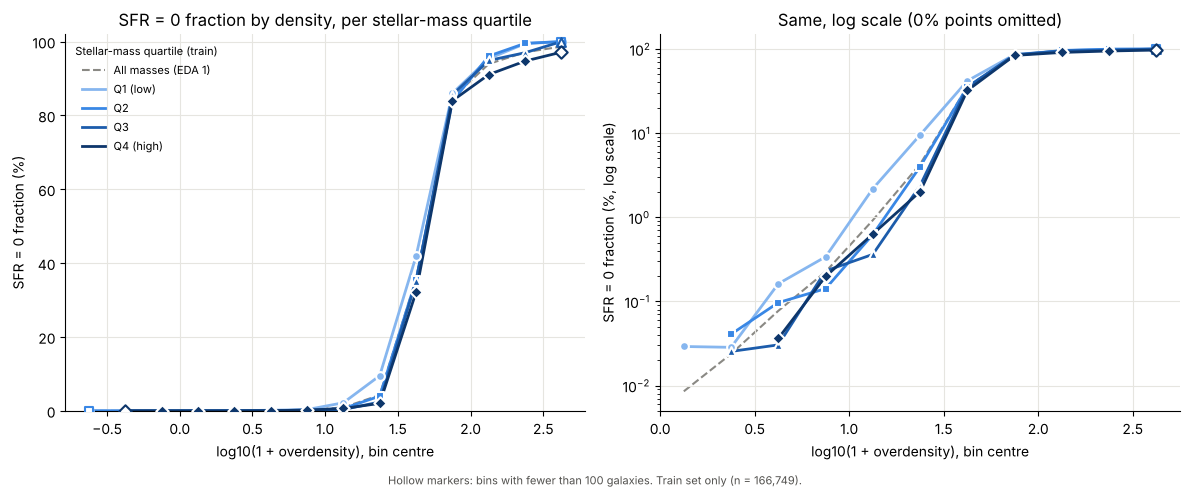

In [19]:
# 그림: 질량 집단별 밀도–SFR=0 비율 곡선 (왼쪽 선형 축, 오른쪽 로그 축으로 낮은 비율까지)
#    색은 질량 순서대로 옅은 파랑 → 진한 파랑, 표본이 100개 미만인 점은 속이 빈 표시
tab2r = tab2.reset_index()
tab2r["밀도 중앙"] = tab2r["밀도 구간"].apply(lambda iv: iv.mid)
overall_curve = zero_by_dens.reset_index()
overall_curve["밀도 중앙"] = overall_curve[DENS].apply(lambda iv: iv.mid)

colors = {"Q1 (low)": "#86b6ef", "Q2": "#3987e5", "Q3": "#1c5cab", "Q4 (high)": "#0d366b"}
markers = {"Q1 (low)": "o", "Q2": "s", "Q3": "^", "Q4 (high)": "D"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, logy in zip(axes, (False, True)):
    oy = overall_curve["SFR=0 비율(%)"]
    ax.plot(overall_curve["밀도 중앙"], oy.where(~(logy & (oy == 0))),
            color="#8a8984", lw=1.5, ls="--", label="All masses (EDA 1)", zorder=1)
    for q, d in tab2r.groupby("질량 집단", observed=True):
        y = d["SFR=0 비율(%)"].where(~(logy & (d["SFR=0 비율(%)"] == 0)))   # 로그 축에서는 0%를 그리지 않는다
        ax.plot(d["밀도 중앙"], y, color=colors[q], lw=2, label=q, zorder=2)
        big = d["은하 수"] >= SMALL_N
        ax.scatter(d.loc[big, "밀도 중앙"], y[big], color=colors[q], marker=markers[q], s=40, zorder=3,
                   edgecolor="white", linewidth=1.5)
        ax.scatter(d.loc[~big, "밀도 중앙"], y[~big], facecolor="white", edgecolor=colors[q], marker=markers[q],
                   s=40, linewidth=1.5, zorder=3)
    ax.set_xlabel("log10(1 + overdensity), bin centre")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#e6e5e0", lw=0.8, zorder=0)
    if logy:
        ax.set_yscale("log"); ax.set_ylim(0.005, 150)
        ax.set_ylabel("SFR = 0 fraction (%, log scale)")
        ax.set_title("Same, log scale (0% points omitted)")
    else:
        ax.set_ylim(0, 102); ax.set_ylabel("SFR = 0 fraction (%)")
        ax.set_title("SFR = 0 fraction by density, per stellar-mass quartile")
axes[0].legend(title="Stellar-mass quartile (train)", fontsize=8, title_fontsize=8, frameon=False, loc="upper left")
fig.text(0.5, -0.02, "Hollow markers: bins with fewer than 100 galaxies. Train set only (n = 166,749).",
         ha="center", fontsize=8, color="#52514e")
plt.tight_layout()
plt.show()


#### EDA 2 코멘트 — 항성 질량을 고려한 주변 밀도와 SFR = 0의 관계 (학습 데이터 166,749개)

**발견**
- 항성 질량을 학습 데이터 분위수로 4개 집단(Q1 낮음 ~ Q4 높음)으로 나눠 비교했다. **네 집단 모두에서 주변 밀도가 높아질수록 SFR = 0 비율이 급격히 증가했다.** 0 비율이 50%를 처음 넘는 구간도 네 집단 모두 (1.75, 2.00]으로 같았다.
- 다만 집단별 곡선이 완전히 같지는 않았다. 예를 들어 밀도 (1.50, 1.75] 구간의 SFR = 0 비율은 **Q1 41.87%, Q4 32.14%로 약 9.7%p 차이**가 있었다. 가장 높은 밀도(2.00, 2.25]에서도 Q4는 91.07%로, 다른 집단(94.88~96.09%)보다 조금 낮았다.

**해석**
- EDA 1은 "주변 밀도와 SFR = 0 사이에 강한 관계가 있다"는 발견이었다. EDA 2는 **항성 질량이 비슷한 집단 안에서도 그 관계가 유지된다**는 추가 확인이다.
- 따라서 이 관계를 질량 집단의 구성 차이만으로 설명하기는 어렵다. 아래 표에서 네 집단의 비율을 같은 가중치로 평균한 곡선도 원래 곡선과 모든 구간에서 0.56%p 이내로 같았다.
- 동시에 특정 밀도 구간에서는 질량별 차이가 있으므로, 항성 질량의 정보도 무시하면 안 된다.

**모델링 시사점 (모델 담당에게)**
- 주변 밀도를 **SFR = 0 여부 예측의 핵심 후보 피처**로 쓰고, **항성 질량도 함께 유지**하는 방향을 제안한다.
- 밀도 하나의 고정 임계값으로 0 여부를 정하기보다, 밀도에 따른 급격한 비율 변화와 질량별 차이를 표현할 수 있는 모델을 실험할 근거로 삼는다. 트리 계열 같은 비선형 모델이 후보가 될 수 있지만, 실제 성능 개선 여부는 모델링 실험으로 확인해야 한다.

**한계**
- "항성 질량을 고려했다"는 것은 질량을 4개 구간으로 나눠 비교했다는 뜻이다. 모든 은하의 질량을 정확히 같게 맞추거나 다른 변수까지 통제한 것은 아니다.
- 이 결과는 통계적 연관이다. 주변 밀도가 별 생성을 멈추게 하는 직접적인 원인이라고 단정하지 않는다.
- 분석 대상은 **SFR이 정확히 0인지 여부**다. 양수 SFR의 크기 예측이나 최종 RMSE에 대한 결론으로 확대하지 않는다.
- 일부 구간은 표본이 적다(위 표의 "적음"·"매우 적음" 표시). 특히 밀도 양 끝 구간의 비율은 해석하지 않는다.


In [20]:
# 질량을 나누기 전과 후 비교
# (1) 집단별 핵심 숫자: 50%를 처음 넘는 밀도 구간, 전환 구간의 0 비율, 낮은 밀도(< 1.0)의 0 비율
rows = []
for q, d in tab2.groupby(level=0, observed=True):
    d = d.droplevel(0)
    ok = d[d["은하 수"] >= SMALL_N]
    first50 = ok.index[ok["SFR=0 비율(%)"] >= 50]
    sub = train[mass_q == q]
    rows.append({
        "질량 집단": q,
        "50% 처음 넘는 구간 (n≥100)": str(first50[0]) if len(first50) else "없음",
        "(1.25,1.5] 0 비율(%)": d["SFR=0 비율(%)"].get(pd.Interval(1.25, 1.5), np.nan),
        "(1.5,1.75] 0 비율(%)": d["SFR=0 비율(%)"].get(pd.Interval(1.5, 1.75), np.nan),
        "(1.75,2.0] 0 비율(%)": d["SFR=0 비율(%)"].get(pd.Interval(1.75, 2.0), np.nan),
        "밀도<1.0 0 비율(%)": (sub.loc[sub[DENS] < 1.0, TARGET] == 0).mean() * 100,
        "밀도≥1.5 0 비율(%)": (sub.loc[sub[DENS] >= 1.5, TARGET] == 0).mean() * 100,
        "밀도≥1.5 SFR>0 수": int((sub.loc[sub[DENS] >= 1.5, TARGET] > 0).sum()),
        "줄어드는 곳 (n≥100끼리)": sum(ok["SFR=0 비율(%)"].diff().dropna() < 0),
    })
overall_row = {"질량 집단": "전체 (나누기 전)",
    "50% 처음 넘는 구간 (n≥100)": str(zero_by_dens.index[zero_by_dens["SFR=0 비율(%)"] >= 50][0]),
    "(1.25,1.5] 0 비율(%)": zero_by_dens.loc[pd.Interval(1.25, 1.5), "SFR=0 비율(%)"],
    "(1.5,1.75] 0 비율(%)": zero_by_dens.loc[pd.Interval(1.5, 1.75), "SFR=0 비율(%)"],
    "(1.75,2.0] 0 비율(%)": zero_by_dens.loc[pd.Interval(1.75, 2.0), "SFR=0 비율(%)"],
    "밀도<1.0 0 비율(%)": (train.loc[train[DENS] < 1.0, TARGET] == 0).mean() * 100,
    "밀도≥1.5 0 비율(%)": (train.loc[train[DENS] >= 1.5, TARGET] == 0).mean() * 100,
    "밀도≥1.5 SFR>0 수": int((train.loc[train[DENS] >= 1.5, TARGET] > 0).sum()),
    "줄어드는 곳 (n≥100끼리)": 0}
display(pd.DataFrame(rows + [overall_row]).set_index("질량 집단").round(2))

# (2) 질량 구성을 똑같이 맞춘 곡선(직접 표준화): 각 밀도 구간에서 네 집단의 0 비율을 같은 가중치(25%)로 평균
wide = tab2["SFR=0 비율(%)"].unstack(level=0)
wide_n = tab2["은하 수"].unstack(level=0)
std_curve = wide.where(wide_n >= SMALL_N).mean(axis=1, skipna=False)
cmp_std = pd.DataFrame({
    "나누기 전 (원래 비율)": zero_by_dens["SFR=0 비율(%)"],
    "질량 구성 맞춤 (4집단 평균, 모두 n≥100일 때만)": std_curve,
})
cmp_std["차이 (%p)"] = cmp_std.iloc[:, 1] - cmp_std.iloc[:, 0]
display(cmp_std.round(2))


,50% 처음 넘는 구간 (n≥100),"(1.25,1.5] 0 비율(%)","(1.5,1.75] 0 비율(%)","(1.75,2.0] 0 비율(%)",밀도<1.0 0 비율(%),밀도≥1.5 0 비율(%),밀도≥1.5 SFR>0 수,줄어드는 곳 (n≥100끼리)
질량 집단,,,,,,,,
Q1 (low),"(1.75, 2.0]",9.51,41.87,85.99,0.10,67.27,1362,1
Q2,"(1.75, 2.0]",3.99,35.44,83.83,0.05,64.17,1703,0
Q3,"(1.75, 2.0]",2.38,35.13,85.59,0.06,66.09,1814,0
Q4 (high),"(1.75, 2.0]",2.02,32.14,83.98,0.07,63.49,2427,0
전체 (나누기 전),"(1.75, 2.0]",4.27,35.70,84.76,0.07,65.06,7306,0


,나누기 전 (원래 비율),"질량 구성 맞춤 (4집단 평균, 모두 n≥100일 때만)",차이 (%p)
"(-0.75, -0.5]",0.00,NaN,NaN
"(-0.5, -0.25]",0.00,NaN,NaN
"(-0.25, 0.0]",0.00,0.00,0.00
"(0.0, 0.25]",0.01,0.01,-0.00
"(0.25, 0.5]",0.02,0.02,-0.00
"(0.5, 0.75]",0.08,0.08,0.00
"(0.75, 1.0]",0.22,0.23,0.00
"(1.0, 1.25]",0.92,0.95,0.03
"(1.25, 1.5]",4.27,4.47,0.20
"(1.5, 1.75]",35.70,36.14,0.44


### 3.1 EDA Findings — **STUDENT RESPONSE**

**Finding 1:** ...  
**Finding 2:** ...  
**Additional finding(s):** ...  

**Modeling decisions motivated by the EDA:** ...

## 4. Data Preparation & Feature Engineering — **STUDENT WORK**

Document all choices that affect model inputs. Discuss feature inclusion/exclusion, missing-value treatment, transformations, scaling, and engineered features where applicable. **`subhalo_id` must not be used as a predictive feature.**

In [21]:
# Default allowed feature set. You may modify FINAL_FEATURES, but never include subhalo_id or sfr_linear.
ALLOWED_FEATURES = [c for c in df.columns if c not in [ID_COLUMN, TARGET]]
FINAL_FEATURES = ALLOWED_FEATURES.copy()

assert ID_COLUMN not in FINAL_FEATURES
assert TARGET not in FINAL_FEATURES
assert set(FINAL_FEATURES).issubset(set(ALLOWED_FEATURES))

X = df[FINAL_FEATURES].copy()
y = df[TARGET].copy()
print(f"Using {len(FINAL_FEATURES)} features:")
print(FINAL_FEATURES)

# STUDENT TODO: add preprocessing / feature engineering if desired.

Using 13 features:
['log10_halo_mass', 'log10_stellar_mass', 'log10_BH_mass', 'log10_main_prog_mass', 'log10_main_prog_stellar_mass', 'log10_mass_ratio', 'log10_overdensity_plus_1', 'pos_x', 'pos_y', 'pos_z', 'vel_x', 'vel_y', 'vel_z']


### 4.1 Preprocessing Rationale — **STUDENT RESPONSE**

| Choice | What you did | Why |
|---|---|---|
| Feature selection |  |  |
| Missing values |  |  |
| Scaling / transformation |  |  |
| Feature engineering |  |  |

**Additional explanation:** ...